In [1]:
import sys
sys.path.insert(0, "../")

import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import lstsq
from src.InverseHeatModel import InverseHeatModel

import torch
import torch.nn as nn

from src.PlottingHandler import plot_mse_t_comparison

from src.print_utils import print_kv, print_section, print_table_header, print_table_row, print_line
from src.window_manager import make_windows, window_loss_full, window_loss_single

device = "cuda" if torch.cuda.is_available() else "cpu"

plt.style.use("../styles/plots.mplstyle")

In [2]:
def convolutivity_test(F,G):
    H = np.divide(G, F, where=(np.abs(F) > 1e-10), 
                       out=np.zeros_like(G))

    error_diag = np.linalg.norm(H * F - G)**2
    
    return H,error_diag

In [3]:
np.random.seed(42)

dati = np.genfromtxt(
    f"../dataset/dataset_eltek/2 Piastre/2026-07-20_Prova Housing -  4 termocoppie(T3 su S1)_ 2 Piastre_Prova 1(.).txt",
    #f"../dataset/dataset_eltek/prova_piastra/2026-07-08_Prova Housing-4 termocoppie_Piastra_Riscaldamento.csv",
    delimiter=";",
    usecols=(0,1,2,3)
)

low_idx = 0
high_idx= -1

T_amb = np.mean(dati[1:10000,0])
Theta_0 = dati[low_idx:high_idx,0] - T_amb
Theta_1 = dati[low_idx:high_idx,1] - T_amb 
Theta_2 = dati[low_idx:high_idx,2] - T_amb # temperatura reale
Theta_3 = dati[low_idx:high_idx,3] - T_amb # sensore

print(T_amb)

25.048148618861887


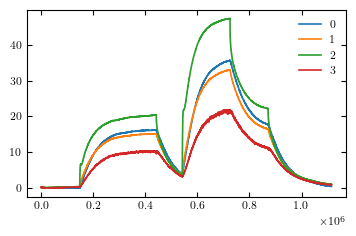

In [4]:
plt.plot(Theta_0, label="0")
plt.plot(Theta_1, label="1")
plt.plot(Theta_2, label="2")
plt.plot(Theta_3, label="3")

plt.legend()

In [5]:
f1 = Theta_2
g1 = Theta_3


In [6]:
dati_ricostruzione = np.genfromtxt(
    #f"../dataset/dataset_eltek/prova_piastra/2026-07-08_Prova Housing-4 termocoppie_Piastra_Riscaldamento.csv",
    f"../dataset/dataset_eltek/2 Piastre/2026-07-21_Prova Housing -  4 termocoppie(T3 su S1)_ 2 Piastre_Prova 2(.).txt",
    delimiter=";",
    usecols=(0,1,2,3)
)

low_idx = 0

T_amb = np.mean(dati[0:10000,0])

g = dati_ricostruzione[low_idx:high_idx,3] - T_amb # sensore
f = dati_ricostruzione[low_idx:high_idx,2] - T_amb # temperatura reale

nt = np.size(g)
n = int(2 * nt - 1)
  
f1=f1[:nt]
g1=g1[:nt]

In [7]:

F = np.fft.rfft(f1, n=n)
G = np.fft.rfft(g1, n=n)
H,loss = convolutivity_test(F,G)

h = np.fft.irfft(H,n=n)[:nt]

lambda_reg = 1

omegas = np.fft.rfftfreq(n, d=0.01) * 2 * np.pi
H_power = np.abs(H)**2
eps = 1e-6 * np.max(H_power)

W_RPM = np.conjugate(H) / (np.abs(H)**2 + lambda_reg*omegas**2 + eps)

In [8]:
from src.Heat1DCrankNicolson import Heat1DCrankNicolson

# Calcolo W con risposta all'impuslo dell'equazione del calore
dt = 1/100
L = 0.0004 + 0.00013
Tf = dt * nt
D = 8.61e-6
wanted_r = 2
h = 2200

n = (2*nt - 1) 

type_used = np.float32

solver = Heat1DCrankNicolson(L,Tf,nt,D,h,wanted_r=wanted_r)
solver.info()

impulse = solver.impulse_response()[solver.nx - 1]


-----------------------------Solver info------------------------------

Diffusion time:                                               3.26e-02
dx:                                                           2.65e-04
dt:                                                           1.00e-02
nt:                                                            1032999
nx:                                                                  3
r:                                                            1.23e+00
h:                                                            2.20e+03


In [9]:
H_tick = np.fft.rfft(impulse,n=n)

H_power = np.abs(H_tick)**2
eps = 1e-6 * np.max(H_power)

W_TICK = np.conjugate(H_tick) / (np.abs(H_tick)**2 + lambda_reg*omegas**2 + eps)

In [16]:
from src.RPM import LearnedTikhonov, train
import torch

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

model = LearnedTikhonov(H=H_tick, n=n, nt=nt, dt=dt, lambda_tik=lambda_reg).to(DEVICE)

G_train = torch.from_numpy(g1[None, :]).to(DEVICE)
F_train = torch.from_numpy(f1[None, :]).to(DEVICE)
G_val = torch.from_numpy(g[None, :]).to(DEVICE)
F_val = torch.from_numpy(f[None, :]).to(DEVICE)

In [ ]:
# ==== DIAGNOSTICA PRIMA DEL TRAINING ====
print("=" * 60)
print("DIAGNOSTICA PRE-TRAINING")
print("=" * 60)

# 1. Verifica forme
print(f"G_train shape: {G_train.shape}, dtype: {G_train.dtype}")
print(f"F_train shape: {F_train.shape}, dtype: {F_train.dtype}")
print(f"G_val shape: {G_val.shape}, dtype: {G_val.dtype}")

# 2. Verifica valori
print(f"\nG_train: min={G_train.min():.2e}, max={G_train.max():.2e}, mean={G_train.mean():.2e}")
print(f"F_train: min={F_train.min():.2e}, max={F_train.max():.2e}, mean={F_train.mean():.2e}")
print(f"H_tick: min={H_tick.min():.2e}, max={H_tick.max():.2e}")

# 3. Forward pass di prova
with torch.no_grad():
    pred_train = model(G_train)
    pred_val = model(G_val)
    
print(f"\nPred_train: min={pred_train.min():.2e}, max={pred_train.max():.2e}")
print(f"Pred_val: min={pred_val.min():.2e}, max={pred_val.max():.2e}")

# 4. Loss iniziale
loss_fn = torch.nn.MSELoss()
initial_loss_train = loss_fn(pred_train, F_train)
initial_loss_val = loss_fn(pred_val, F_val)

print(f"\nInitial MSE (train): {initial_loss_train.item():.4e}")
print(f"Initial MSE (val): {initial_loss_val.item():.4e}")

# 5. Verifica gradienti
model.train()
optimizer = torch.optim.Adam(model.parameters(), lr=5e-4)
loss = loss_fn(model(G_train), F_train)
loss.backward()

grad_norm = 0
for name, param in model.named_parameters():
    if param.grad is not None:
        g_norm = param.grad.norm().item()
        if g_norm > 1e-10:
            print(f"Gradient {name}: norm={g_norm:.2e}")
            grad_norm += g_norm**2

print(f"Total gradient norm: {grad_norm**0.5:.2e}")

if grad_norm < 1e-12:
    print("\n WARNING: Gradienti quasi zero! C'è un problema nel calcolo.")
else:
    print("\n Gradienti OK, procedi con il training.")

print("=" * 60)

DIAGNOSTICA PRE-TRAINING
G_train shape: torch.Size([1, 1032999]), dtype: torch.float64
F_train shape: torch.Size([1, 1032999]), dtype: torch.float64
G_val shape: torch.Size([1, 1032999]), dtype: torch.float64

G_train: min=-4.92e-02, max=2.19e+01, mean=8.67e+00
F_train: min=3.88e-02, max=4.75e+01, mean=1.79e+01
H_tick: min=-2.56e+01-9.00e+00j, max=4.62e+01+0.00e+00j

Pred_train: min=-1.86e+00, max=4.66e+01
Pred_val: min=-2.38e+00, max=4.59e+01

Initial MSE (train): 9.3934e+00
Initial MSE (val): 1.0345e+01
Gradient phi_raw: norm=4.83e+01
Gradient log_R: norm=6.23e+00
Total gradient norm: 4.87e+01

✅ Gradienti OK, procedi con il training.


In [20]:

history, _ = train(
    model=model,
    G_train=G_train,
    F_train=F_train,
    G_val=G_val,
    F_val=F_val,
    n_epochs=500,
    lr=5e-4,  # Ridotto
    weight_decay=0.0,
    lambda_smooth=0,  # Aggiunto
    scheduler_type="Cosine",
    checkpoint_path="../assets/eltek/best_tikhonov.pt",
)

Epoch     1/500 | train MSE: 9.3934e+00 | val MSE: 1.0289e+01 | lr: 5.00e-04
Epoch    50/500 | train MSE: 6.4551e+00 | val MSE: 7.5591e+00 | lr: 4.99e-04
Epoch   100/500 | train MSE: 4.3273e+00 | val MSE: 5.4019e+00 | lr: 4.97e-04
Epoch   150/500 | train MSE: 2.8590e+00 | val MSE: 3.9507e+00 | lr: 4.93e-04
Epoch   200/500 | train MSE: 1.9578e+00 | val MSE: 3.1984e+00 | lr: 4.88e-04
Epoch   250/500 | train MSE: 1.4295e+00 | val MSE: 2.8078e+00 | lr: 4.81e-04
Epoch   300/500 | train MSE: 1.1138e+00 | val MSE: 2.6223e+00 | lr: 4.73e-04
Epoch   350/500 | train MSE: 9.2982e-01 | val MSE: 2.6033e+00 | lr: 4.63e-04
Epoch   400/500 | train MSE: 8.3050e-01 | val MSE: 2.6882e+00 | lr: 4.52e-04
Epoch   450/500 | train MSE: 7.6289e-01 | val MSE: 2.8028e+00 | lr: 4.40e-04
Epoch   500/500 | train MSE: 7.1096e-01 | val MSE: 2.9306e+00 | lr: 4.27e-04
Best val MSE                                                2.5890e+00
Saved to                                     ../assets/eltek/best_tikhonov.pt


In [33]:
checkpoint = torch.load("../assets/eltek/best_tikhonov.pt")
model.load_state_dict(checkpoint['model_state'])
print(f"Loaded epoch {checkpoint['epoch']} with val_loss={checkpoint['val_loss']:.4e}")

model.eval()
with torch.no_grad():
    f_rec_rpm = model(G_val).cpu().numpy()[0]  # Output in frequenza

# Trasforma indietro nel tempo
#f_rec_rpm = np.fft.irfft(F_rec_rpm, n=n)[:nt]

g_trap = np.empty_like(g)
g_trap[:-1] = (g[:-1] + g[1:]) / 2
g_trap[-1] = g[-1] / 2
                
G = np.fft.rfft(g_trap, n)
F = np.fft.rfft(f, n=n)

F_rec_tick = W_TICK*G/0.01
f_rec_tick = np.fft.irfft(F_rec_tick, n=n)[:nt]

# MSE sul dominio del tempo
mse_rpm = np.mean((f_rec_rpm[:len(f)] - f)**2)
mse_tick = np.mean((f_rec_tick[:len(f)] - f)**2)

print(f"MSE RPM:      {mse_rpm:.4e}")
print(f"MSE Tikhonov: {mse_tick:.4e}")

Loaded epoch 329 with val_loss=2.5890e+00
MSE RPM:      2.5890e+00
MSE Tikhonov: 2.3266e+01


/tmp/ipykernel_41237/1008628720.py:149: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


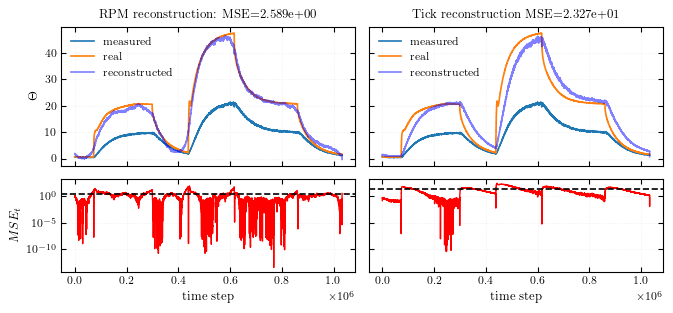

In [ ]:
# Assicuriamoci che i segnali abbiano la stessa lunghezza
N = min(
    len(f),
    len(g),
    len(f_rec_rpm),
    len(f_rec_tick)
)

f_plot = f[:N]
g_plot = g[:N]
f_rec_rpm_plot = f_rec_rpm[:N]
f_rec_tick_plot = f_rec_tick[:N]

# Errori di ricostruzione
error_rpm = f_rec_rpm_plot - f_plot
error_tick = f_rec_tick_plot - f_plot

# Errore quadratico istantaneo
mse_t_rpm = error_rpm**2
mse_t_tick = error_tick**2

# MSE medio globale
mse_rpm = np.mean(mse_t_rpm)
mse_tick = np.mean(mse_t_tick)


# ============================================================
# FIGURA: due ricostruzioni affiancate
# ============================================================

fig, axes = plt.subplots(
    2, 2,
    figsize=(6.8, 3.2),
    sharex="col",
    sharey="row",
    gridspec_kw={"height_ratios": [3, 2]}
)

ax1, ax2 = axes[:, 0]
ax3, ax4 = axes[:, 1]


# ============================================================
# RICOSTRUZIONE RPM - GRAFICO SUPERIORE
# ============================================================

ax1.plot(
    g_plot,
    label="measured"
)

ax1.plot(
    f_plot,
    label="real"
)

ax1.plot(
    f_rec_rpm_plot,
    label="reconstructed",
    c="b",
    alpha=0.5
)

ax1.set_title(f"RPM: MSE={mse_rpm:.3e}")
ax1.set_ylabel(r"$\Theta$")
ax1.grid(True, alpha=0.3)
ax1.legend()


# ============================================================
# RICOSTRUZIONE RPM - MSE
# ============================================================

ax2.plot(
    mse_t_rpm,
    color="red",
    linewidth=1,
    label=r"$(f_{\mathrm{rec}}-f)^2$"
)

ax2.axhline(
    mse_rpm,
    color="black",
    linestyle="--",
    linewidth=1.2,
    label=f"MSE = {mse_rpm:.3e}"
)

ax2.set_xlabel("time step")
ax2.set_ylabel(r"$MSE_t$")
ax2.grid(True, alpha=0.3)
ax2.set_yscale("log")


# ============================================================
# RICOSTRUZIONE TICK - GRAFICO SUPERIORE
# ============================================================

ax3.plot(
    g_plot,
    label="measured"
)

ax3.plot(
    f_plot,
    label="real"
)

ax3.plot(
    f_rec_tick_plot,
    label="reconstructed",
    c="b",
    alpha=0.5
)

ax3.set_title(f"Tickonov: MSE={mse_tick:.3e}")
ax3.grid(True, alpha=0.3)
ax3.legend()


# ============================================================
# RICOSTRUZIONE TICK - MSE
# ============================================================

ax4.plot(
    mse_t_tick,
    color="red",
    linewidth=1,
    label=r"$(f_{\mathrm{rec}}-f)^2$"
)

ax4.axhline(
    mse_tick,
    color="black",
    linestyle="--",
    linewidth=1.2,
    label=f"MSE = {mse_tick:.3e}"
)

ax4.set_xlabel("time step")
ax4.grid(True, alpha=0.3)
ax4.set_yscale("log")


# ============================================================
# LAYOUT E SALVATAGGIO
# ============================================================

plt.tight_layout()

plt.savefig(
    "../assets/eltek/ricostruzione_eletek_rpm_tick.pdf",
    dpi=150,
    bbox_inches="tight"
)

plt.show()